### Cell 1 — Setup & Imports

In [ ]:
import os, shutil, random, zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from PIL import Image
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
import torchvision
from torchvision import datasets, transforms, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score,
                             recall_score, f1_score,
                             confusion_matrix, log_loss)


SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {DEVICE}")


Using device: cuda


### Cell 2 — Mount Drive, Extract & Standardize Images to .jpg

In [ ]:

from google.colab import drive
drive.mount('/content/drive')

ZIP_PATH    = '/content/drive/MyDrive/X-Ray_Dataset.zip'
EXTRACT_TO  = '/content/xray_raw'
DATASET_DIR = '/content/xray_dataset'

with zipfile.ZipFile(ZIP_PATH, 'r') as z:
    z.extractall(EXTRACT_TO)


raw_root = Path(EXTRACT_TO)
subdirs = [d for d in raw_root.iterdir() if d.is_dir()]
if len(subdirs) == 1:
    raw_root = subdirs[0]

print("Raw folder contents:", [d.name for d in raw_root.iterdir() if d.is_dir()])


CLASSES = sorted([d.name for d in raw_root.iterdir() if d.is_dir()])
print("Classes found:", CLASSES)

for cls in CLASSES:
    src_dir = raw_root / cls
    dst_dir = Path(DATASET_DIR) / cls
    dst_dir.mkdir(parents=True, exist_ok=True)

    for idx, fpath in enumerate(sorted(src_dir.iterdir())):
        if not fpath.is_file():
            continue
        try:
            with Image.open(fpath) as img:
                img = img.convert('RGB')
                dst_path = dst_dir / f"{cls}_{idx:04d}.jpg"
                img.save(dst_path, 'JPEG', quality=95)
        except Exception as e:
            print(f"  Skipped {fpath.name}: {e}")

for cls in CLASSES:
    n = len(list((Path(DATASET_DIR) / cls).glob('*.jpg')))
    print(f"  {cls}: {n} .jpg images")

print("\nAll images standardized to .jpg")


Mounted at /content/drive
Raw folder contents: ['Covid', 'Normal']
Classes found: ['Covid', 'Normal']
  Covid: 196 .jpg images
  Normal: 196 .jpg images

All images standardized to .jpg


### Cell 3 — Explore the Data

Class distribution:
  Covid: 196 images
  Normal: 196 images
  Total: 392 images


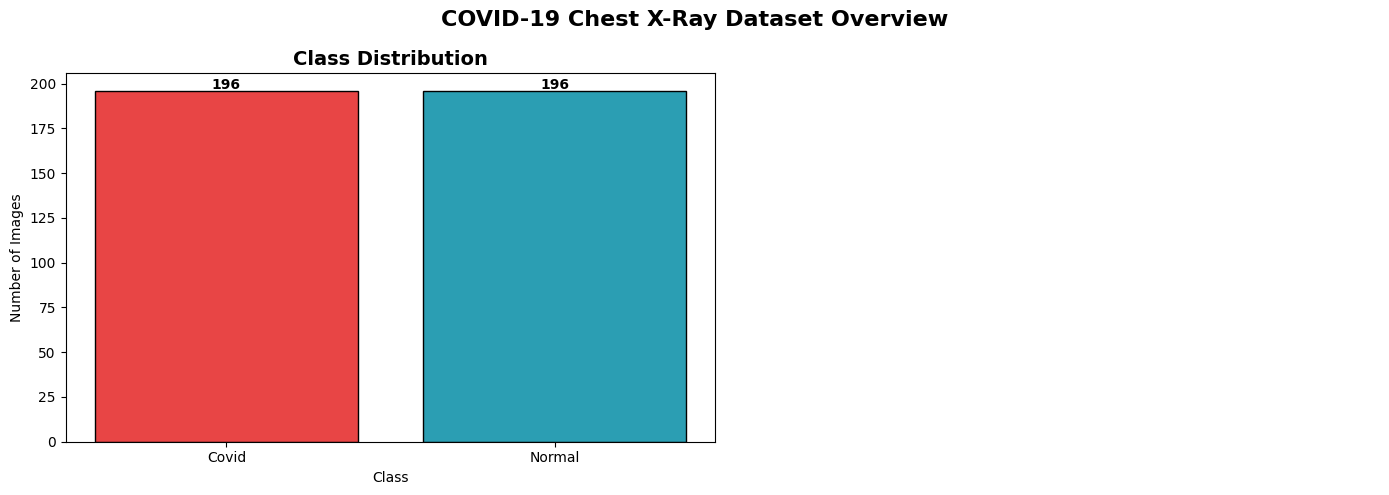

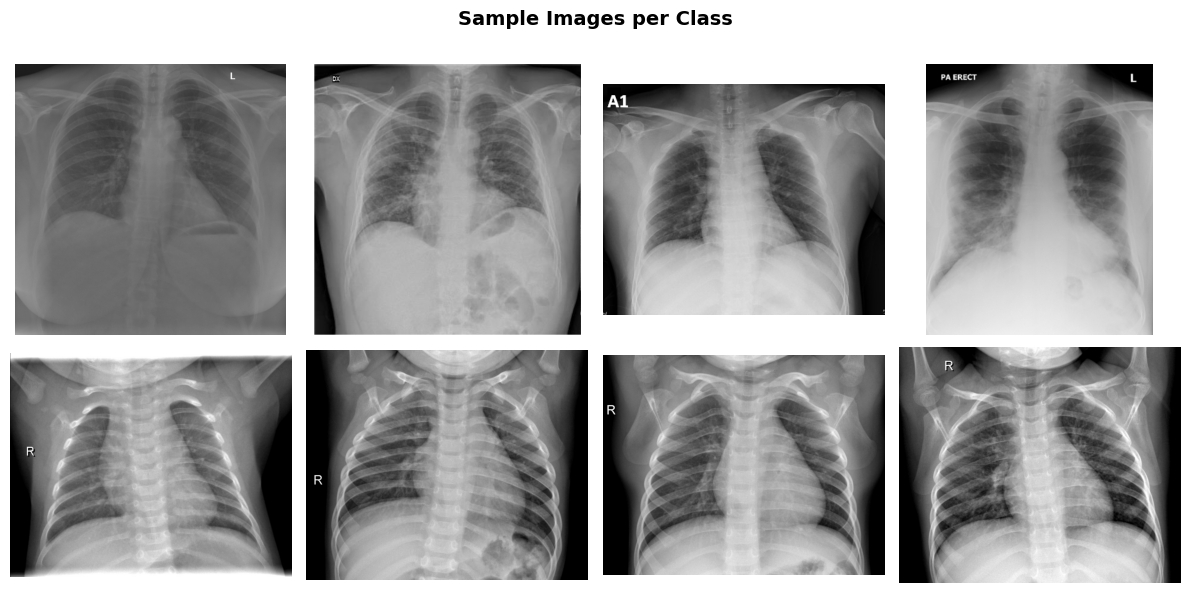

In [ ]:


print("Class distribution:")
class_counts = {}
for cls in CLASSES:
    count = len(list((Path(DATASET_DIR) / cls).glob('*.jpg')))
    class_counts[cls] = count
    print(f"  {cls}: {count} images")
print(f"  Total: {sum(class_counts.values())} images")


fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(class_counts.keys(), class_counts.values(),
            color=['#E84545', '#2B9EB3'], edgecolor='black')
axes[0].set_title('Class Distribution', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Number of Images')
axes[0].set_xlabel('Class')
for i, (k, v) in enumerate(class_counts.items()):
    axes[0].text(i, v + 1, str(v), ha='center', fontweight='bold')

axes[1].axis('off')
fig.suptitle('COVID-19 Chest X-Ray Dataset Overview', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

n_samples = 4
fig, axes = plt.subplots(len(CLASSES), n_samples,
                         figsize=(n_samples * 3, len(CLASSES) * 3))
fig.suptitle('Sample Images per Class', fontsize=14, fontweight='bold', y=1.01)

for row, cls in enumerate(CLASSES):
    all_imgs = sorted((Path(DATASET_DIR) / cls).glob('*.jpg'))
    samples  = random.sample(all_imgs, n_samples)
    for col, img_path in enumerate(samples):
        ax = axes[row][col]
        img = Image.open(img_path)
        ax.imshow(img, cmap='gray')
        ax.axis('off')
        if col == 0:
            ax.set_ylabel(cls, fontsize=12, fontweight='bold', rotation=0,
                          labelpad=55, va='center')

plt.tight_layout()
plt.show()


### Cell 4 — Build Dataset & Train / Test Split

In [ ]:

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.RandomCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.3, contrast=0.3),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])


test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

full_dataset = datasets.ImageFolder(DATASET_DIR, transform=test_transform)
print("Class to index mapping:", full_dataset.class_to_idx)


targets = [label for _, label in full_dataset.samples]
train_idx, test_idx = train_test_split(
    range(len(full_dataset)),
    test_size=0.20,
    stratify=targets,
    random_state=SEED
)


train_dataset_full = datasets.ImageFolder(DATASET_DIR, transform=train_transform)
train_subset = Subset(train_dataset_full, train_idx)
test_subset  = Subset(full_dataset, test_idx)

BATCH_SIZE = 32
train_loader = DataLoader(train_subset, batch_size=BATCH_SIZE,
                          shuffle=True,  num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_subset,  batch_size=BATCH_SIZE,
                          shuffle=False, num_workers=2, pin_memory=True)

print(f"Train samples : {len(train_subset)}")
print(f"Test  samples : {len(test_subset)}")
print(f"Batch size    : {BATCH_SIZE}")
print(f"Train batches : {len(train_loader)}")
print(f"Test  batches : {len(test_loader)}")


Class to index mapping: {'Covid': 0, 'Normal': 1}
Train samples : 313
Test  samples : 79
Batch size    : 32
Train batches : 10
Test  batches : 3


### Cell 5 — Build the Model (ResNet-18 Transfer Learning)

In [ ]:
NUM_CLASSES   = 2
LEARNING_RATE = 1e-4
NUM_EPOCHS    = 15


model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)

for param in model.parameters():
    param.requires_grad = False

in_features = model.fc.in_features
model.fc = nn.Sequential(
    nn.Dropout(p=0.5),
    nn.Linear(in_features, NUM_CLASSES)
)

model = model.to(DEVICE)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=LEARNING_RATE
)


trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total     = sum(p.numel() for p in model.parameters())
print(f"Trainable parameters : {trainable:,} / {total:,}")
print(f"Learning rate        : {LEARNING_RATE}")
print(f"Epochs               : {NUM_EPOCHS}")
print(f"Batch size           : {BATCH_SIZE}")
print(f"Loss function        : CrossEntropyLoss")
print(f"Optimizer            : Adam")



Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 176MB/s]


Trainable parameters : 1,026 / 11,177,538
Learning rate        : 0.0001
Epochs               : 15
Batch size           : 32
Loss function        : CrossEntropyLoss
Optimizer            : Adam


### Cell 6 — Baseline: Measure the Model BEFORE Training

In [ ]:


def evaluate(model, loader, criterion, device):
    """Run model on loader; return loss, accuracy, and all preds/labels/probs."""
    model.eval()
    all_labels, all_preds, all_probs = [], [], []
    total_loss = 0.0

    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss    = criterion(outputs, labels)
            total_loss += loss.item() * images.size(0)

            probs = torch.softmax(outputs, dim=1).cpu().numpy()
            preds = outputs.argmax(dim=1).cpu().numpy()

            all_labels.extend(labels.cpu().numpy())
            all_preds.extend(preds)
            all_probs.extend(probs)

    avg_loss  = total_loss / len(loader.dataset)
    acc       = accuracy_score(all_labels, all_preds)
    precision = precision_score(all_labels, all_preds, average='binary', zero_division=0)
    recall    = recall_score(all_labels, all_preds,    average='binary', zero_division=0)
    f1        = f1_score(all_labels, all_preds,        average='binary', zero_division=0)

    return {
        'loss': avg_loss, 'accuracy': acc,
        'precision': precision, 'recall': recall, 'f1': f1,
        'labels': all_labels, 'preds': all_preds, 'probs': all_probs
    }


print("Evaluating model on test set BEFORE training...")
before = evaluate(model, test_loader, criterion, DEVICE)

print(f"\n{'Metric':<12} {'Before Training':>16}")
print("-" * 30)
for metric in ['loss', 'accuracy', 'precision', 'recall', 'f1']:
    print(f"{metric.capitalize():<12} {before[metric]:>16.4f}")




Evaluating model on test set BEFORE training...

Metric        Before Training
------------------------------
Loss                   1.0007
Accuracy               0.3544
Precision              0.4118
Recall                 0.7179
F1                     0.5234


---
## Member 2 - Training, Curves, Evaluation and Results
---


### Cell 7 — Train the Model

In [ ]:
train_losses, train_accuracies = [], []

print(f"Training for {NUM_EPOCHS} epochs on {DEVICE}...\n")
print(f"{'Epoch':<8} {'Train Loss':>12} {'Train Acc':>12}")
print("-" * 34)

for epoch in range(1, NUM_EPOCHS + 1):
    model.train()
    epoch_loss, correct, total = 0.0, 0, 0

    for images, labels in train_loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)

        optimizer.zero_grad()
        outputs = model(images)
        loss    = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item() * images.size(0)
        preds      = outputs.argmax(dim=1)
        correct   += (preds == labels).sum().item()
        total     += labels.size(0)

    avg_loss = epoch_loss / total
    acc      = correct / total
    train_losses.append(avg_loss)
    train_accuracies.append(acc)

    print(f"{epoch:<8} {avg_loss:>12.4f} {acc:>12.4f}")

print("\nTraining complete")


Training for 15 epochs on cuda...

Epoch      Train Loss    Train Acc
----------------------------------
1              0.8392       0.5112
2              0.8337       0.4952
3              0.7710       0.5176
4              0.6998       0.5815
5              0.7211       0.5942
6              0.7216       0.5527
7              0.6814       0.5911
8              0.6259       0.6454
9              0.6272       0.6294
10             0.6011       0.6613
11             0.5506       0.7029
12             0.5440       0.7348
13             0.5284       0.7508
14             0.5136       0.7764
15             0.5050       0.7572

Training complete


### Cell 8 — Plot Training Curves

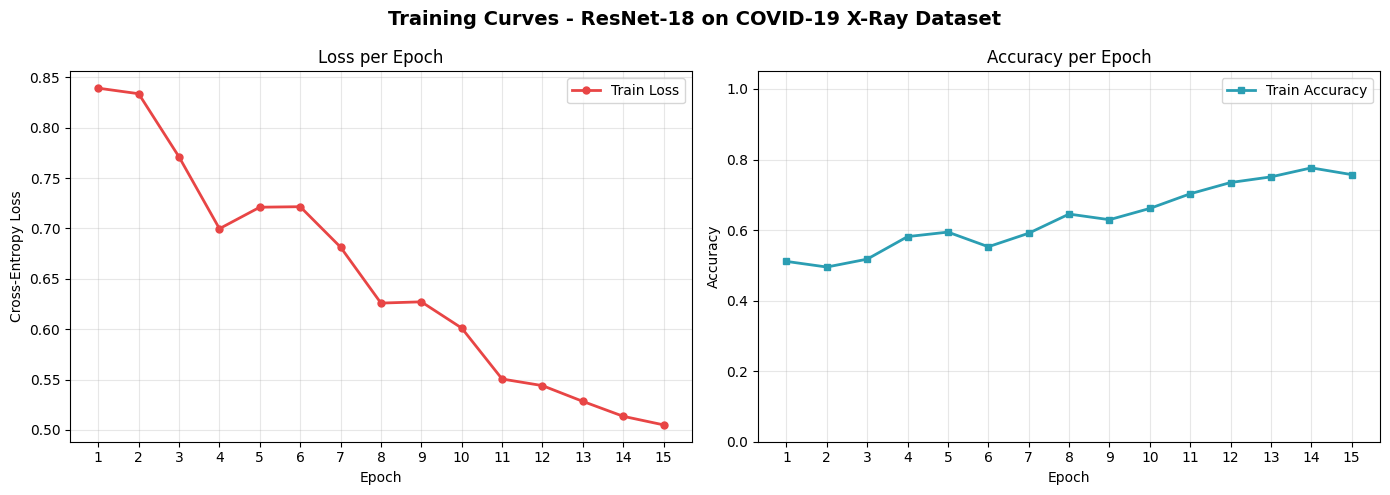

In [ ]:

epochs_range = range(1, NUM_EPOCHS + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Training Curves - ResNet-18 on COVID-19 X-Ray Dataset',
             fontsize=14, fontweight='bold')


ax1.plot(epochs_range, train_losses, 'o-', color='#E84545',
         linewidth=2, markersize=5, label='Train Loss')
ax1.set_title('Loss per Epoch')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Cross-Entropy Loss')
ax1.legend()
ax1.grid(alpha=0.3)
ax1.set_xticks(epochs_range)


ax2.plot(epochs_range, train_accuracies, 's-', color='#2B9EB3',
         linewidth=2, markersize=5, label='Train Accuracy')
ax2.set_title('Accuracy per Epoch')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy')
ax2.set_ylim(0, 1.05)
ax2.legend()
ax2.grid(alpha=0.3)
ax2.set_xticks(epochs_range)

plt.tight_layout()
plt.savefig('training_curves.png', dpi=150, bbox_inches='tight')
plt.show()





**The training curves show that the model is still learning, with training loss decreasing from 0.8392 (epoch 1) to 0.5050 (epoch 15) and training accuracy rising from 0.5112 to 0.7572.**




### Cell 9 — Evaluate AFTER Training + Confusion Matrix

Evaluating model on test set AFTER training...

Metric         After Training
------------------------------
Loss                   0.4701
Accuracy               0.7595
Precision              0.6724
Recall                 1.0000
F1                     0.8041


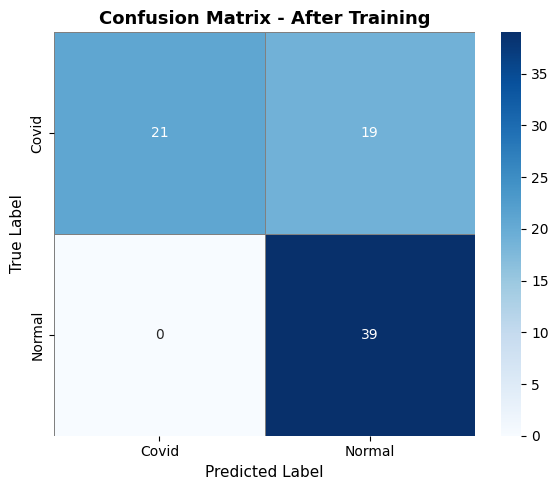

In [ ]:


print("Evaluating model on test set AFTER training...")
after = evaluate(model, test_loader, criterion, DEVICE)

print(f"\n{'Metric':<12} {'After Training':>16}")
print("-" * 30)
for metric in ['loss', 'accuracy', 'precision', 'recall', 'f1']:
    print(f"{metric.capitalize():<12} {after[metric]:>16.4f}")


CLASS_NAMES = list(full_dataset.class_to_idx.keys())
cm = confusion_matrix(after['labels'], after['preds'])

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
            linewidths=0.5, linecolor='gray', ax=ax)
ax.set_title('Confusion Matrix - After Training', fontsize=13, fontweight='bold')
ax.set_xlabel('Predicted Label', fontsize=11)
ax.set_ylabel('True Label', fontsize=11)
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()


### Cell 10 — Before vs After Comparison Table

In [ ]:


print("Before vs After Training Comparison")
print("-" * 45)
print(f"{'Metric':<12} {'Before':>10} {'After':>10} {'Change':>10}")
print("-" * 45)

metrics = ['loss', 'accuracy', 'precision', 'recall', 'f1']
for m in metrics:
    b = before[m]
    a = after[m]
    diff = a - b
    sign = "+" if diff >= 0 else ""
    print(f"{m.capitalize():<12} {b:>10.4f} {a:>10.4f} {sign}{diff:>9.4f}")

print("-" * 45)




Before vs After Training Comparison
---------------------------------------------
Metric           Before      After     Change
---------------------------------------------
Loss             1.0007     0.4701   -0.5306
Accuracy         0.3544     0.7595 +   0.4051
Precision        0.4118     0.6724 +   0.2606
Recall           0.7179     1.0000 +   0.2821
F1               0.5234     0.8041 +   0.2808
---------------------------------------------


**After training on the same 79-image test set, loss dropped by -0.5306, accuracy improved by +0.4051 (from 0.3544 to 0.7595), and F1 increased by +0.2808 (from 0.5234 to 0.8041). This happened because training the new head over 15 epochs adapted ResNet-18 features to chest X-ray images, while the confusion matrix shows 39/39 Normal images predicted correctly and 21/40 Covid images predicted correctly (with 19 Covid images misclassified as Normal).**

### Cell 11 — Save the Trained Model

In [ ]:


SAVE_PATH = '/content/drive/MyDrive/covid_resnet18_finetuned.pth'
torch.save({
    'model_state_dict'    : model.state_dict(),
    'class_to_idx'        : full_dataset.class_to_idx,
    'num_epochs_trained'  : NUM_EPOCHS,
    'final_train_accuracy': train_accuracies[-1],
    'final_train_loss'    : train_losses[-1],
    'test_accuracy_after' : after['accuracy'],
}, SAVE_PATH)

print(f"Model saved to: {SAVE_PATH}")
print(f"Final train accuracy : {train_accuracies[-1]:.4f}")
print(f"Test  accuracy after : {after['accuracy']:.4f}")


Model saved to: /content/drive/MyDrive/covid_resnet18_finetuned.pth
Final train accuracy : 0.7572
Test  accuracy after : 0.7595


### Cell 12 — Display Up to 2 Misclassified Test Images

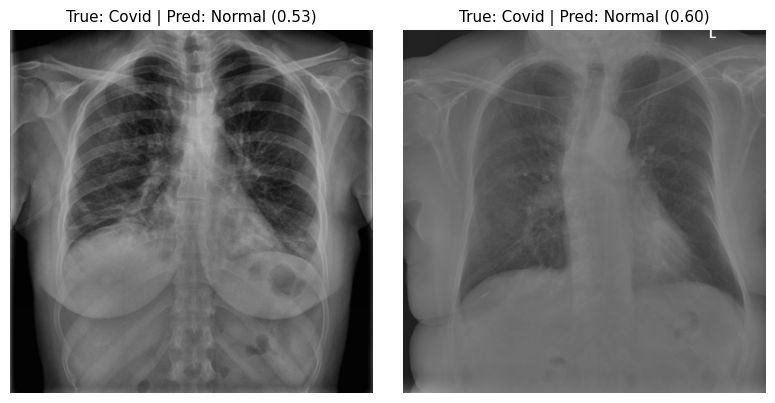

In [ ]:

model.eval()
wrong_samples = []

with torch.no_grad():
    for subset_idx, dataset_idx in enumerate(test_idx):
        img_path, true_idx = full_dataset.samples[dataset_idx]
        x, _ = test_subset[subset_idx]
        x = x.unsqueeze(0).to(DEVICE)

        logits = model(x)
        probs = torch.softmax(logits, dim=1).squeeze(0).cpu().numpy()
        pred_idx = int(logits.argmax(dim=1).item())

        if pred_idx != true_idx:
            wrong_samples.append({
                "path": img_path,
                "true": CLASS_NAMES[true_idx],
                "pred": CLASS_NAMES[pred_idx],
                "pred_prob": float(probs[pred_idx]),
            })
        if len(wrong_samples) == 2:
            break

fig, axes = plt.subplots(1, len(wrong_samples), figsize=(8, 4))
if len(wrong_samples) == 1:
    axes = [axes]

for ax, item in zip(axes, wrong_samples):
    ax.imshow(Image.open(item["path"]).convert("RGB"))
    ax.set_title(
        f"True: {item['true']} | Pred: {item['pred']} ({item['pred_prob']:.2f})",
        fontsize=11
    )
    ax.axis("off")

plt.tight_layout()
plt.show()